
## Model and validation

The inputs are 21-day and 63-day momentum, momentum from 252 to 21 days ago, 63-day volatility, 252-day drawdown, momentum relative to the index, and recent momentum acceleration. Trends may continue; volatility and drawdown measure risk. Ridge is a simple linear model that limits large fitted weights when inputs are closely related.

We compare alpha values 1, 100, and 1,000 with chronological folds in 2013 and 2014. Training uses only earlier signals with completed returns; clipping, imputation, and scaling learn from training rows. We use 2015 to compare predictions with the training-average baseline and choose 10 or 20 stocks by Sharpe. We then fit once on 2010-2015 signals with outcomes finished before March 31, 2016. The settings are fixed before the April 1, 2016 to September 30, 2026 test.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import pandas as pd
from IPython.display import Image, Markdown, display

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "pyproject.toml").is_file())
project = root / "Homeworks/HW4/Weitao_Su"
results = project / "results"

REBUILD = False
if REBUILD or not (results / "summary.json").exists():
    subprocess.run([sys.executable, "-B", str(project / "run_project.py")],
                   cwd=root, check=True)
summary = json.loads((results / "summary.json").read_text(encoding="utf-8"))


def show_performance(frame):
    table = frame.copy()
    formats = {"final_value": "${:,.2f}", "CAGR": "{:.2%}",
               "max_drawdown": "{:.2%}", "Sharpe": "{:.3f}"}
    for column, fmt in formats.items():
        table[column] = table[column].map(lambda value: fmt.format(value) if pd.notna(value) else "Unavailable")
    display(table)

Full model training and backtest completed through September 30, 2026.


In [2]:
print("Ridge alpha comparison:")
display(pd.DataFrame(summary["model_selection"]))
print("2015 prediction check:")
display(pd.DataFrame(summary["validation"]).set_index("metric").round(4))
print("2015 comparison of buying 10 or 20 stocks:")
show_performance(pd.DataFrame(summary["strategy_selection"]))
settings = summary["settings"]
print(f"Selected alpha: {settings['alpha']:g}; stocks per month: {settings['top_n']}.")
print("Last training outcome:", settings["last_training_outcome"])

Ridge alpha comparison:


,alpha,RMSE
0,1,0.202679
1,100,0.202659
2,1000,0.202561


2015 prediction check:


,Ridge,Baseline
metric,,
RMSE,0.1649,0.1611
MAE,0.1202,0.1183
R2,-0.1748,-0.1214
mean_daily_rank_IC,-0.1066,NaN
IC_dates,9.0000,0.0000


2015 comparison of buying 10 or 20 stocks:


,top_n,final_value,CAGR,max_drawdown,Sharpe
0,10,"$797,700.20",-20.34%,-29.04%,-0.768
1,20,"$780,917.68",-22.03%,-34.70%,-0.779


Selected alpha: 1000; stocks per month: 10.
Last training outcome: 2016-02-29


## Trading rules

- Start with $1 million, long only, with no borrowing. Use the entry quarter's stock list, including inactive names. Keep owned stocks after they leave the list.
- Require a raw price of at least $5, a 21-day average dollar volume of at least $10 million, and 63-day annualized volatility of at most 80%.
- Rank after the last close before each month's first session; buy at that next close. Set budgets before the fill: up to one-third of account value using available cash, split equally, with a planned 5% limit per ticker. Later price moves can raise weights above that limit.
- Track each purchase separately. Sell after 90 calendar days, at the first market close on or after maturity. Include open holdings at the September 30, 2026 close.
- Use fractional adjusted-price units and charge 0.05% per stock trade. Cash earns zero. Adjusted prices already include dividends.
- Skip missing-price entries and keep cash. Apply verified acquisition terms to existing holdings; reserve cash payouts until original maturity and keep that date for replacement shares. Payouts have no trading fee. Unknown missing holding prices stop the run.


Last backtest day: 2026-09-30


,final_value,CAGR,max_drawdown,Sharpe
portfolio,,,,
Strategy,"$2,163,468.46",7.63%,-51.02%,0.354
S&P 500 total return,"$4,402,746.78",15.17%,-33.79%,0.773


Strategy minus index: $-2,239,278.32 (-223.93 percentage points of total return).


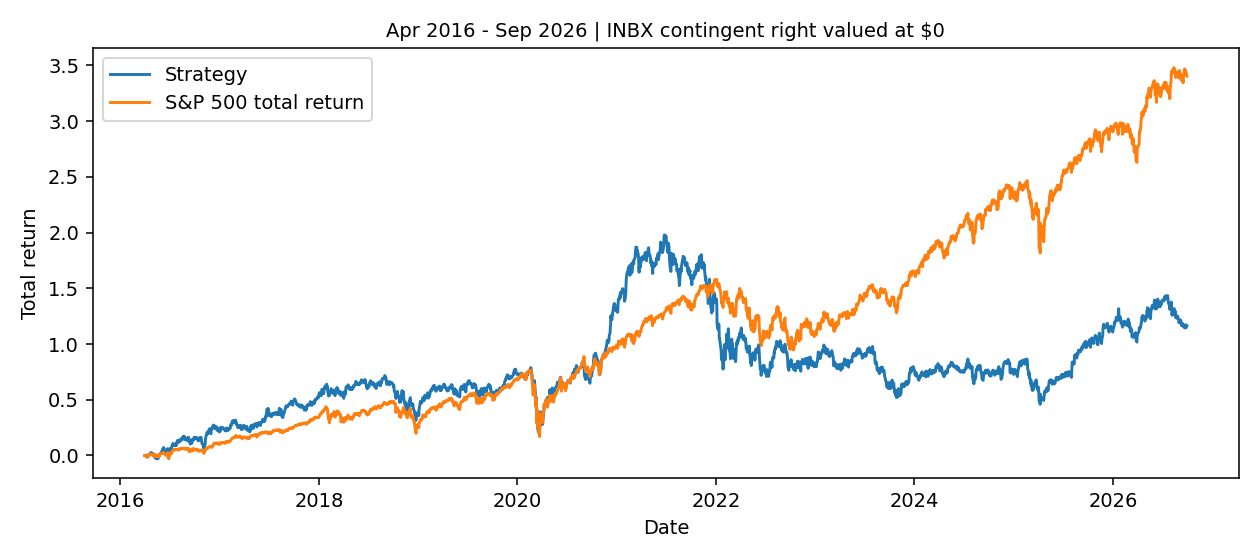

In [3]:
run = summary["run"]
print("Last backtest day:", run["last_date"])
if run["problem"]:
    display(Markdown("**Incomplete run:** " + run["problem"]))
performance = pd.DataFrame(summary["performance"]).set_index("portfolio")
show_performance(performance)
if not run["problem"]:
    difference = performance.loc["Strategy", "final_value"] - performance.loc["S&P 500 total return", "final_value"]
    print(f"Strategy minus index: ${difference:,.2f} ({difference / settings['initial_cash'] * 100:+.2f} percentage points of total return).")
    assert abs(performance.loc["Strategy", "final_value"] - run["ending_cash"] - run["ending_holdings"]) < 1e-6
display(Image(filename=str(results / "cumulative_returns.png")))

## Findings

The strategy finished below the index, with a deeper drawdown. In 2015, Ridge predicted less accurately than the training-average baseline and ranked stocks poorly, which suggests a weak stock-selection signal. We then kept that model unchanged for more than ten years, so it could not adapt to changing market conditions; this may help explain the later underperformance.

Both stock groups lost money in 2015. Next, I would test retraining with completed outcomes, financial features, and another model using development data.

## Acquisitions and open holdings

[corporate_actions.csv](corporate_actions.csv) records the verified terms and sources. Old INBX shares became $30 cash, a quarter-share in the new company, and a contingent payment right. The CSV supplies the replacement stock's observed $15.86 INXB close on May 30, 2024, absent from the database; the stock was sold on that lot's maturity date. The contingent right remains recorded separately and cannot be sold under the normal 90-day rule.

In [4]:
print(f"Ending cash: ${run['ending_cash']:,.2f}; stock holdings and reserved payouts: ${run['ending_holdings']:,.2f}.")
print("Open stock purchases:", len(summary["open_lots"]))
rights = pd.DataFrame(summary["open_rights"])
if not rights.empty:
    display(rights[["symbol", "units", "maximum_per_unit", "assumed_value"]])
    maximum = (rights.units * rights.maximum_per_unit).sum()
    print(f"Maximum additional cash from contingent rights: ${maximum:,.2f}.")
    print("Adding that amount to ending value would not change the benchmark conclusion.")

Ending cash: $930,306.22; stock holdings and reserved payouts: $1,233,162.24.
Open stock purchases: 20


,symbol,units,maximum_per_unit,assumed_value
0,INBX,863.382979,5.0,0.0


Maximum additional cash from contingent rights: $4,316.91.
Adding that amount to ending value would not change the benchmark conclusion.


## Accounting checks and limits

The tests check cash, costs, profit, 90-day timing, separate purchases, open positions, missing prices, and acquisition payouts. The backtester also reconciles daily cash to recorded trades. A full-data review independently reconstructed daily cash and holdings and checked order budgets, membership, observed fills, and sale dates.

Old prices, share counts, ticker histories, and acquisition coverage can be incomplete or wrong. The source ranking audit flags unusual values without excluding stocks based on future events. Multiple tickers may represent one company. Repeated purchases, 90-day lockups, and changing market conditions add risk. Costs omit taxes, settlement delays, and market impact.

In [5]:
print(f"Completed sessions: {run['sessions']}; trades: {run['trades']}; corporate events: {run['corporate_events']}.")
print("Unusual source ranking rows:", run["ranking_flags"])
checked = subprocess.run(
    [sys.executable, "-B", "-m", "unittest", "discover", "-s", str(project), "-p", "test_accounting.py"],
    cwd=root, check=True, capture_output=True, text=True)
print(checked.stderr.strip())

Completed sessions: 2640; trades: 2500; corporate events: 43.
Unusual source ranking rows: 364


....................
----------------------------------------------------------------------
Ran 20 tests in 0.177s

OK


## Sources

Data and model helpers are reused from [course_data.py](../../../Lectures/modeling/course_data.py)

`results/summary.json` holds the tables, chosen settings, open stock purchases, and contingent rights. New runs save detailed daily values, trades, orders, corporate events, and ranking flags in the ignored `outputs/` folder.